In [3]:
!pip -q install factor-analyzer
!wget -O wine.csv https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/wine.csv

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro

from sklearn.preprocessing import StandardScaler

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (
    calculate_bartlett_sphericity,
    calculate_kmo
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

RANDOM_STATE = 42

df = pd.read_csv('wine.csv')

df.head()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-11-26 03:01:59--  https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/wine.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10782 (11K) [text/plain]
Saving to: ‘wine.csv’

wine.csv            100%[===================>]  10.53K  --.-KB/s    in 0s      

2026-11-26 03:01:59 (90.9 MB/s) - ‘wine.csv’ saved [10782/10782]



,1,14.23,1.71,2.43,15.6,127,2.8,3.06,.28,2.29,5.64,1.04,3.92,1065
0,1,13.2000,1.7800,2.1400,11.2000,100,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050
1,1,13.1600,2.3600,2.6700,18.6000,101,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185
2,1,14.3700,1.9500,2.5000,16.8000,113,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480
3,1,13.2400,2.5900,2.8700,21.0000,118,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735
4,1,14.2000,1.7600,2.4500,15.2000,112,3.2700,3.3900,0.3400,1.9700,6.7500,1.0500,2.8500,1450


# Дискриптивный анализ

In [12]:
df = pd.read_csv(
    'wine.csv',
    header=None
)

columns = [
    'Cultivator',
    'Alcohol',
    'Malic_Acid',
    'Ash',
    'Alcalinity_of_Ash',
    'Magnesium',
    'Total_Phenols',
    'Flavanoids',
    'Nonflavanoid_Phenols',
    'Proanthocyanins',
    'Color_Intensity',
    'Hue',
    'OD280_OD315',
    'Proline'
]

df.columns = columns
X = df.drop(columns='Cultivator')
X.head()
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Alcalinity_of_Ash     178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280_OD315           178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [13]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)

descriptive_stats = pd.DataFrame({
    'mean': X.mean(),
    'median': X.median(),
    'std': X.std(),
    'min': X.min(),
    'q1': q1,
    'q3': q3,
    'iqr': q3 - q1,
    'max': X.max(),
    'skew': X.skew(),
    'kurtosis': X.kurtosis()
})

descriptive_stats.round(4)


,mean,median,std,min,q1,q3,iqr,max,skew,kurtosis
Alcohol,13.0006,13.0500,0.8118,11.0300,12.3625,13.6775,1.3150,14.8300,-0.0515,-0.8525
Malic_Acid,2.3363,1.8650,1.1171,0.7400,1.6025,3.0825,1.4800,5.8000,1.0397,0.2992
Ash,2.3665,2.3600,0.2743,1.3600,2.2100,2.5575,0.3475,3.2300,-0.1767,1.1440
Alcalinity_of_Ash,19.4949,19.5000,3.3396,10.6000,17.2000,21.5000,4.3000,30.0000,0.2130,0.4879
Magnesium,99.7416,98.0000,14.2825,70.0000,88.0000,107.0000,19.0000,162.0000,1.0982,2.1050
Total_Phenols,2.2951,2.3550,0.6259,0.9800,1.7425,2.8000,1.0575,3.8800,0.0866,-0.8356
Flavanoids,2.0293,2.1350,0.9989,0.3400,1.2050,2.8750,1.6700,5.0800,0.0253,-0.8804
Nonflavanoid_Phenols,0.3619,0.3400,0.1245,0.1300,0.2700,0.4375,0.1675,0.6600,0.4502,-0.6372
Proanthocyanins,1.5909,1.5550,0.5724,0.4100,1.2500,1.9500,0.7000,3.5800,0.5171,0.5546
Color_Intensity,5.0581,4.6900,2.3183,1.2800,3.2200,6.2000,2.9800,13.0000,0.8686,0.3815


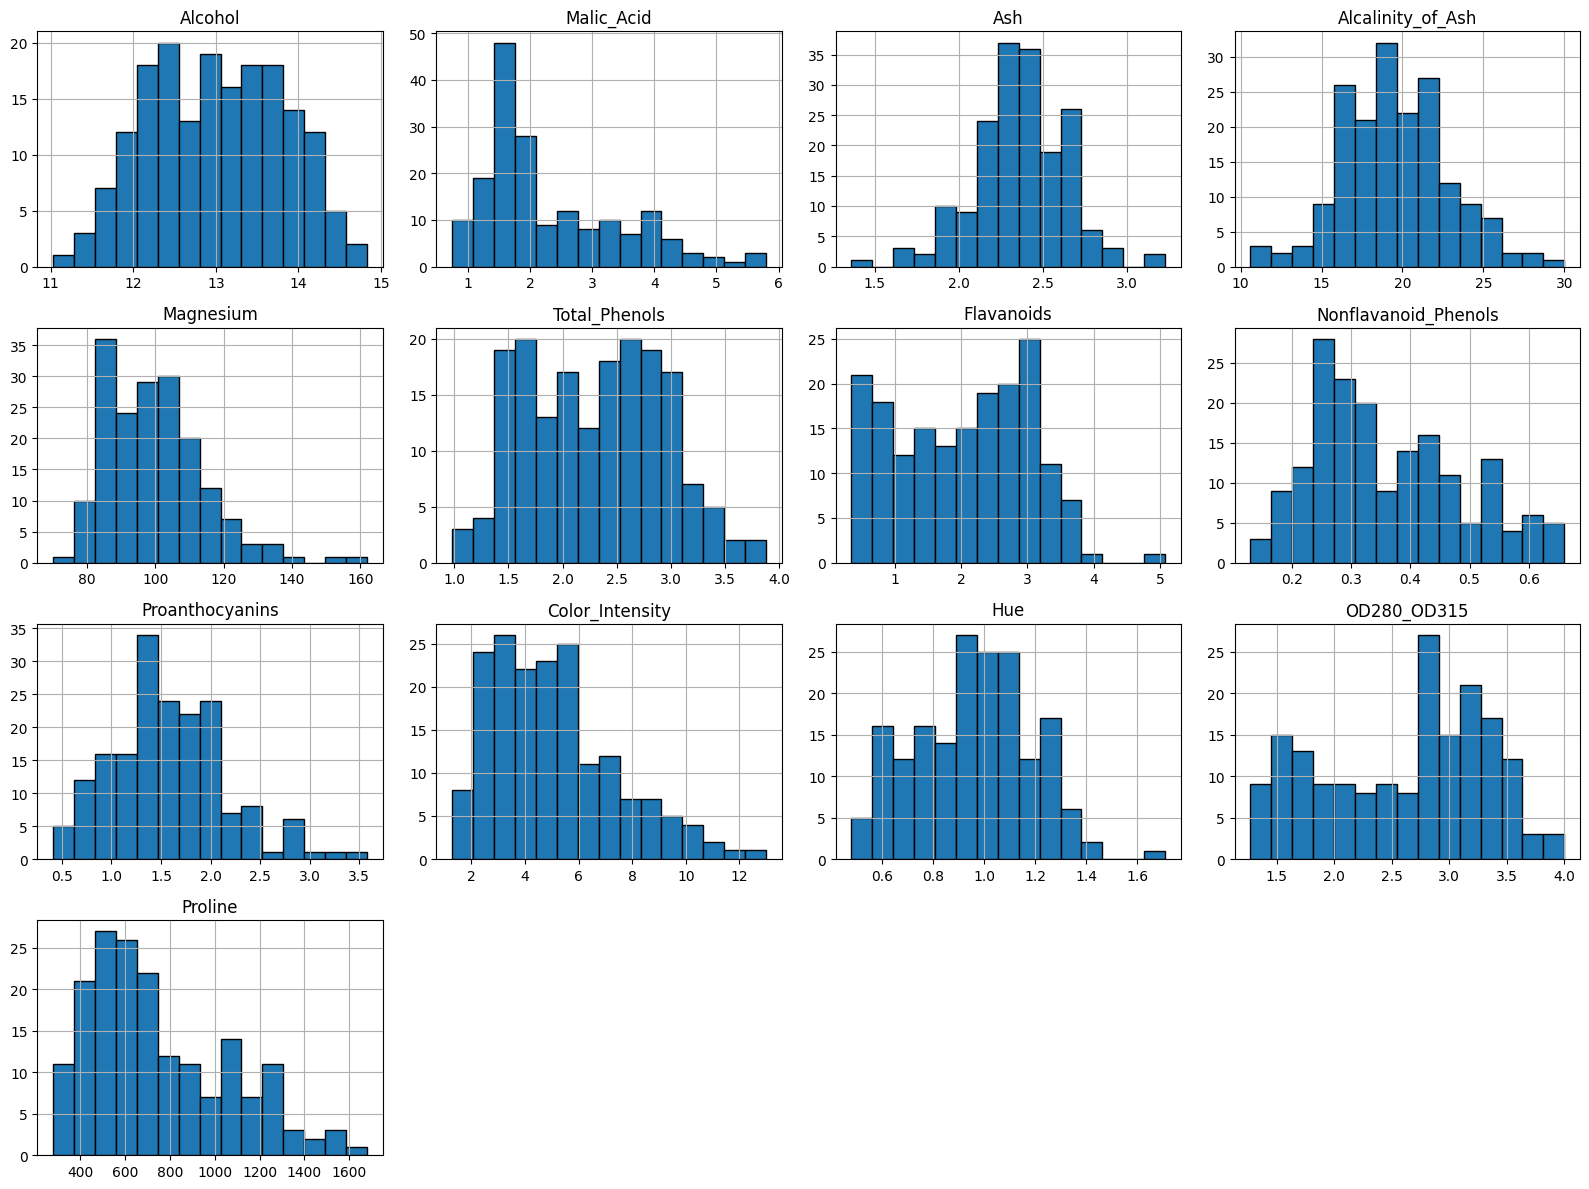

In [16]:
X.hist(
    bins=15,
    figsize=(16, 12),
    edgecolor='black'
)

plt.tight_layout()
plt.show()


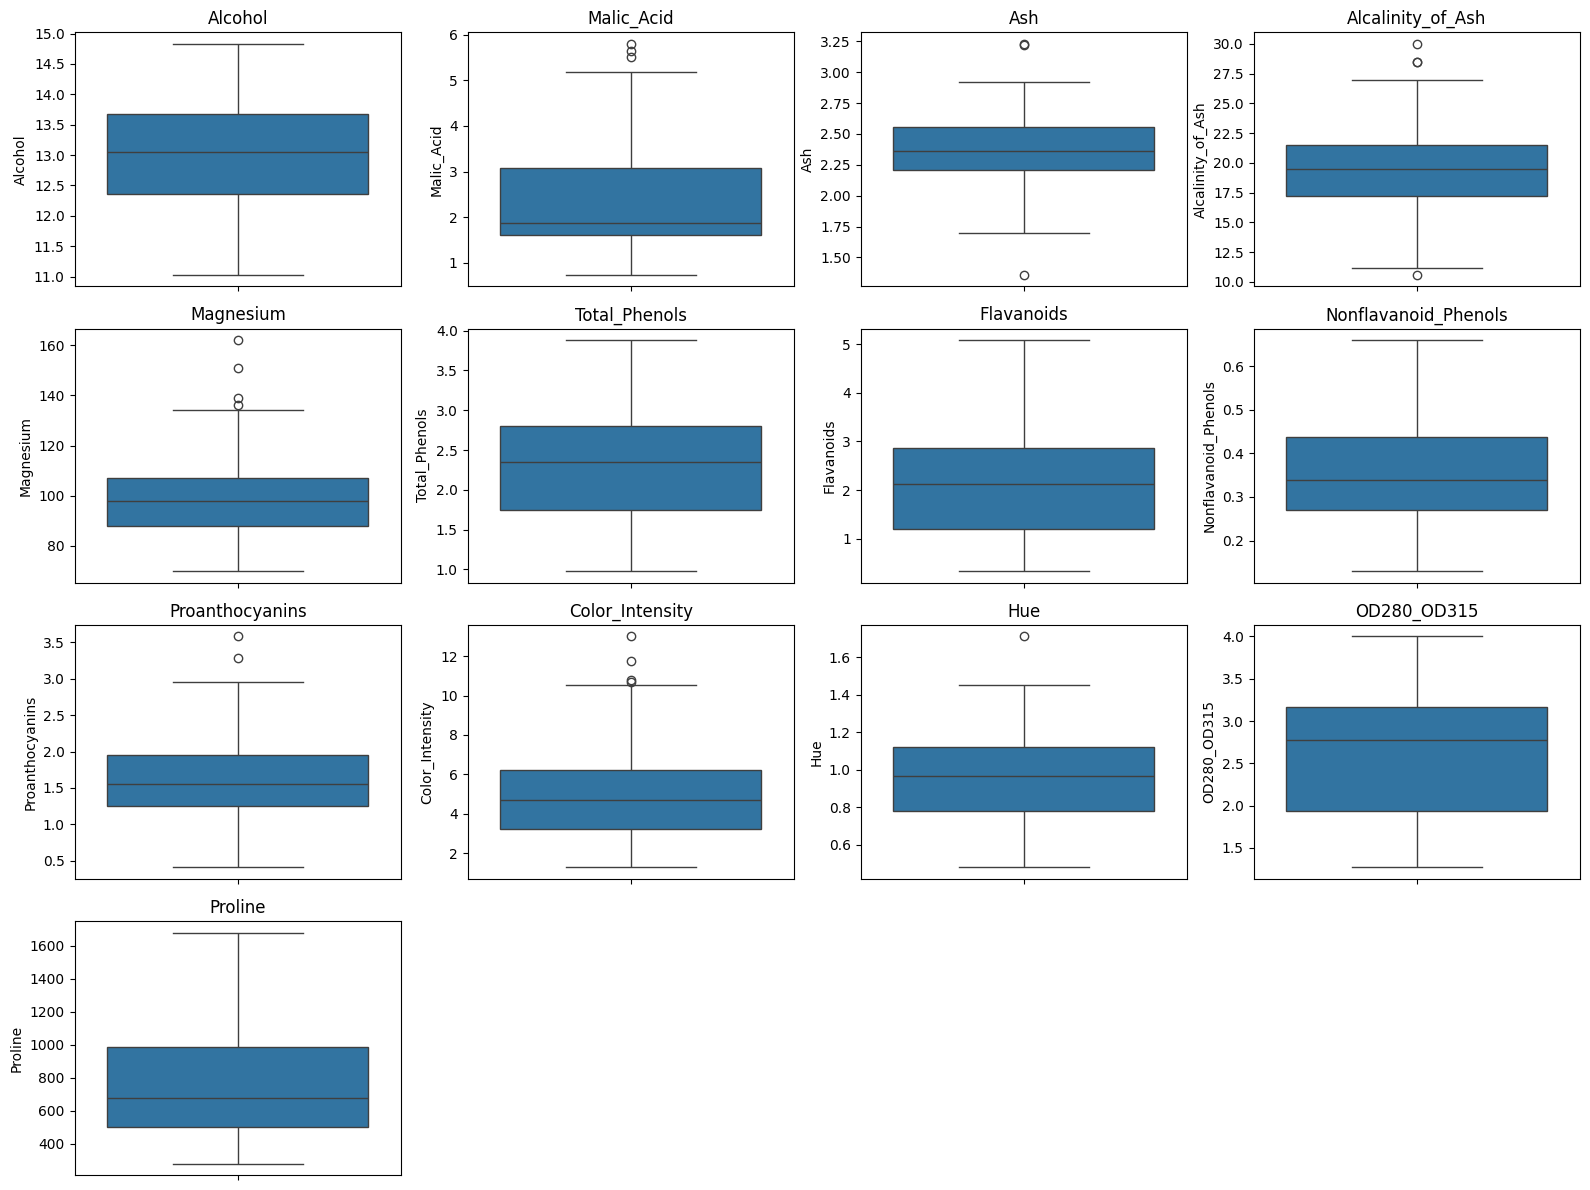

In [17]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.boxplot(
        y=X[column],
        ax=axes[i]
    )

    axes[i].set_title(column)

for i in range(len(X.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Корреляционный анализ

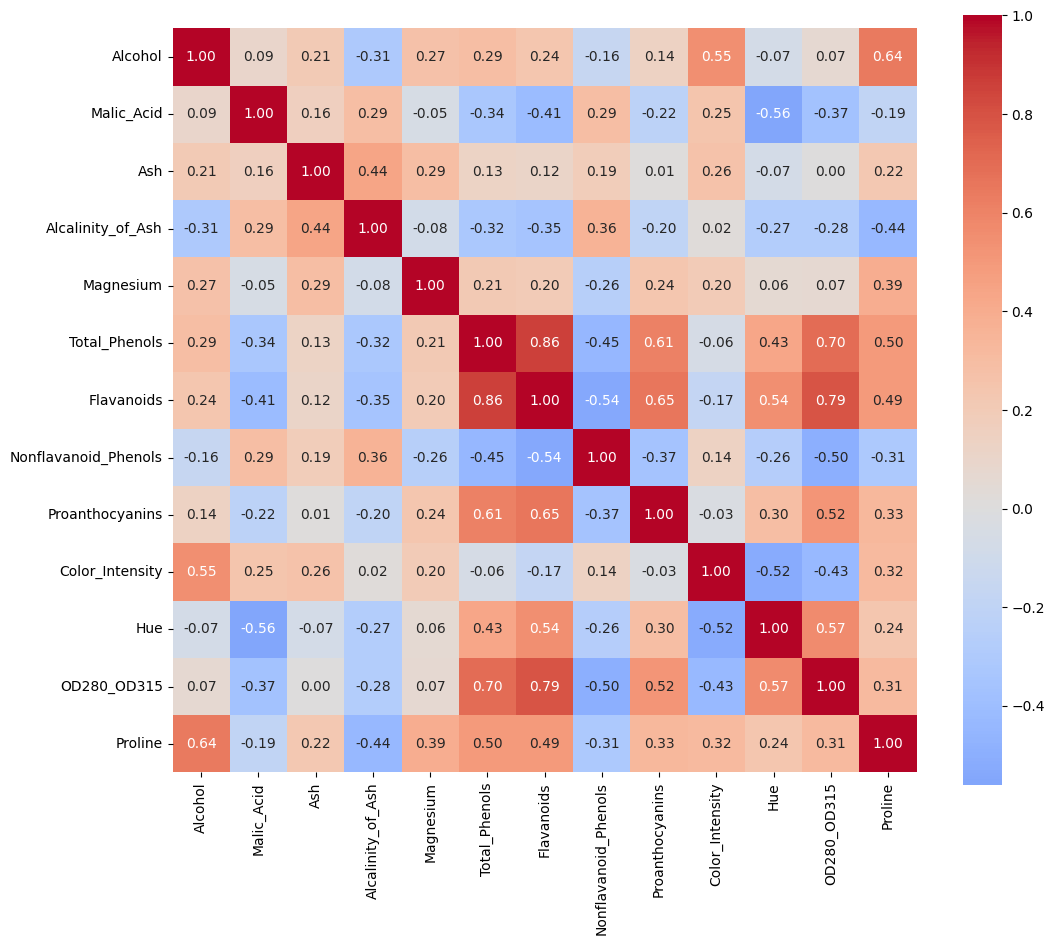

,,0
Total_Phenols,Flavanoids,0.8646
Flavanoids,OD280_OD315,0.7872
Total_Phenols,OD280_OD315,0.6999
Flavanoids,Proanthocyanins,0.6527
Alcohol,Proline,0.6437
Total_Phenols,Proanthocyanins,0.6124
Hue,OD280_OD315,0.5655
Malic_Acid,Hue,-0.5613
Alcohol,Color_Intensity,0.5464
Flavanoids,Hue,0.5435


In [20]:
corr_matrix = X.corr()

corr_matrix.round(3)
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)

plt.show()

corr_pairs = (
    corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

corr_pairs.head(15)

In [21]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

X_scaled.head()

,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline
0,1.5186,-0.5622,0.2321,-1.1696,1.9139,0.8090,1.0348,-0.6596,1.2249,0.2517,0.3622,1.8479,1.0130
1,0.2463,-0.4994,-0.8280,-2.4908,0.0181,0.5686,0.7336,-0.8207,-0.5447,-0.2933,0.4061,1.1134,0.9652
2,0.1969,0.0212,1.1093,-0.2687,0.0884,0.8090,1.2155,-0.4984,2.1360,0.2690,0.3183,0.7886,1.3951
3,1.6915,-0.3468,0.4879,-0.8093,0.9309,2.4914,1.4665,-0.9819,1.0322,1.1861,-0.4275,1.1841,2.3346
4,0.2957,0.2277,1.8404,0.4519,1.2820,0.8090,0.6634,0.2268,0.4014,-0.3193,0.3622,0.4496,-0.0379
